<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Implementa el modelo **RFM** (Recency, Frequency, Monetary) para segmentar clientes
segun su comportamiento de compra, usando los datos unificados en la capa **silver**.

Flujo: `silver/merge_pyspark` ---> calculo RFM ---> scoring por percentiles
---> asignacion de segmentos ---> `gold/rfm_segmentos`

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [2]:
# Inicializar SparkSession
spark = SparkSession.builder \
    .appName("HYM_RFM") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "50") \
    .config("spark.memory.fraction", "0.8") \
    .getOrCreate()

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Rutas de capas

In [3]:
SILVER = "./silver"
GOLD   = "./gold"

import os
os.makedirs(GOLD, exist_ok=True)

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Carga desde capa silver

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Lee el DataFrame unificado desde `silver/merge_pyspark`.
Solo se seleccionan las tres columnas necesarias para el calculo RFM:
`customer_id`, `Fecha` y `price`.

In [4]:
%%time
df_raw = spark.read.parquet(f"{SILVER}/merge_pyspark")

df_clean = (
    df_raw
    .select("customer_id", "Fecha", "price")
    .filter(F.col("price").isNotNull())
)

df_clean.createOrReplaceTempView("clean_transactions")
print(f"Registros cargados: {df_clean.count():,}")

Registros cargados: 31,788,324
CPU times: user 5.79 ms, sys: 3.56 ms, total: 9.35 ms
Wall time: 4.6 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Calculo de variables RFM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula las tres metricas RFM en una sola pasada SQL para minimizar shuffles:

- **Recency (Days)**: dias entre la ultima y penultima compra (ventana `LAG` por cliente).
- **Frequency**: numero total de transacciones del cliente.
- **Monetary (Sold)**: suma del precio pagado por el cliente.

In [5]:
%%time
df_rfm_raw = spark.sql("""
WITH ranked AS (
    SELECT
        customer_id,
        price,
        Fecha,
        LAG(Fecha) OVER (PARTITION BY customer_id ORDER BY Fecha) AS prev_fecha,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY Fecha DESC) AS rnum
    FROM clean_transactions
),
lastbuy AS (
    SELECT customer_id, DATEDIFF(Fecha, prev_fecha) AS Days
    FROM ranked
    WHERE rnum = 1 AND prev_fecha IS NOT NULL
),
freq_amount AS (
    SELECT
        customer_id,
        COUNT(1)      AS Frequency,
        SUM(price)    AS Monetary
    FROM clean_transactions
    GROUP BY customer_id
)
SELECT
    f.customer_id,
    CAST(f.Frequency AS INT)   AS Frequency,
    CAST(f.Monetary      AS FLOAT) AS Monetary,
    CAST(l.Days      AS INT)   AS Recency
FROM freq_amount f
INNER JOIN lastbuy l ON f.customer_id = l.customer_id
""")

df_rfm_raw = df_rfm_raw.checkpoint()
print(f"Clientes con RFM completo: {df_rfm_raw.count():,}")
df_rfm_raw.describe().show()

Clientes con RFM completo: 914,308
+-------+--------------------+------------------+------------------+------------------+
|summary|         customer_id|         Frequency|          Monetary|           Recency|
+-------+--------------------+------------------+------------------+------------------+
|  count|              914308|            914308|            914308|            914308|
|   mean|                null|33.072049025055016|0.9214713859626225| 95.34116293415347|
| stddev|                null| 44.71914776355066|1.3806829749912866|118.92354897115973|
|    min|00000dbacae5abe5e...|                 2|      0.0033559322|                 1|
|    max|ffffd7744cebcf3ac...|              1895|         57.676407|               731|
+-------+--------------------+------------------+------------------+------------------+

CPU times: user 22.9 ms, sys: 7.56 ms, total: 30.5 ms
Wall time: 26.6 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Scoring RFM por percentiles

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Asigna un score del 1 al 5 a cada cliente por dimension, usando quintiles calculados
con ventanas de Spark (no se traen datos al driver):

- **recency_score**: score inverso, menor `Days` = mas reciente = mayor score.
- **frequency_score**: score directo, mayor frecuencia = mayor score.

Se omite Monetary del scoring porque ya esta representado en la frecuencia y el analisis
de segmentacion se basa en el comportamiento temporal.

In [6]:
# Ventanas de calculo de percentiles
w_recency   = Window.orderBy(F.col("Recency").asc())       # menor Days = mas reciente
w_frequency = Window.orderBy(F.col("Frequency").asc())  # mayor Frequency = mejor

df_scored = (
    df_rfm_raw
    .withColumn("recency_pct",   F.percent_rank().over(w_recency))
    .withColumn("frequency_pct", F.percent_rank().over(w_frequency))
    .withColumn("recency_score",
        F.when(F.col("recency_pct") <= 0.2, 5)
         .when(F.col("recency_pct") <= 0.4, 4)
         .when(F.col("recency_pct") <= 0.6, 3)
         .when(F.col("recency_pct") <= 0.8, 2)
         .otherwise(1)
    )
    .withColumn("frequency_score",
        F.when(F.col("frequency_pct") <= 0.2, 1)
         .when(F.col("frequency_pct") <= 0.4, 2)
         .when(F.col("frequency_pct") <= 0.6, 3)
         .when(F.col("frequency_pct") <= 0.8, 4)
         .otherwise(5)
    )
    .withColumn("RFM_score",
        F.concat_ws("",
            F.col("recency_score").cast("string"),
            F.col("frequency_score").cast("string")
        )
    )
)

df_scored = df_scored.checkpoint()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Asignacion de segmentos

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Mapea el codigo `RFM_score` a segmentos de negocio usando expresiones regulares.
La logica de segmentacion sigue el esquema clasico de RFM:

| RFM score | Segmento |
|-----------|----------|
| [1-2][1-2] | hibernating |
| [1-2][3-4] | at_risk |
| [1-2]5     | cant_loose |
| 3[1-2]     | about_to_sleep |
| 33         | need_attention |
| [3-4][4-5] | loyal_customers |
| 41         | promising |
| 51         | new_customers |
| [4-5][2-3] | potential_loyalists |
| 5[4-5]     | champions |


In [7]:
seg_map = {
    r'[1-2][1-2]': 'hibernating',
    r'[1-2][3-4]': 'at_risk',
    r'[1-2]5':     'cant_loose',
    r'3[1-2]':     'about_to_sleep',
    r'33':         'need_attention',
    r'[3-4][4-5]': 'loyal_customers',
    r'41':         'promising',
    r'51':         'new_customers',
    r'[4-5][2-3]': 'potential_loyalists',
    r'5[4-5]':     'champions',
}

segment_col = F.lit(None).cast("string")
for pattern, label in seg_map.items():
    segment_col = F.when(F.col("RFM_score").rlike(pattern), label).otherwise(segment_col)

df_final = (
    df_scored
    .withColumn("segment", segment_col)
    .select("customer_id", "Frequency", "Monetary", "Recency",
            "recency_score", "frequency_score", "RFM_score", "segment")
)

df_final.show(10)

+--------------------+---------+-----------+-------+-------------+---------------+---------+-------------+
|         customer_id|Frequency|   Monetary|Recency|recency_score|frequency_score|RFM_score|      segment|
+--------------------+---------+-----------+-------+-------------+---------------+---------+-------------+
|06e8dc25483b97427...|        2|0.084711865|      1|            5|              1|       51|new_customers|
|092305fca46deb4a4...|        2| 0.05081356|      1|            5|              1|       51|new_customers|
|0add630fc6660b884...|        2|0.055898305|      1|            5|              1|       51|new_customers|
|0b23e27a0809b2f65...|        2|0.033864405|      1|            5|              1|       51|new_customers|
|10a7bac13e534dd24...|        2|  0.2730339|      1|            5|              1|       51|new_customers|
|1a2b8298fe0000c16...|        2|0.071152546|      1|            5|              1|       51|new_customers|
|1e05aa7d397016abc...|        2| 0.09

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 7. Analisis de segmentos

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula metricas por segmento directamente en Spark para evitar traer datos al driver.
Solo se recopila el agregado (una fila por segmento) para graficar.

In [8]:
perfil_seg = (
    df_final.groupBy("segment")
    .agg(
        F.count("customer_id").alias("n_clientes"),
        F.avg("Frequency").alias("freq_media"),
        F.avg("Monetary").alias("monetary_media"),
        F.avg("Recency").alias("recency_media")
    )
    .orderBy(F.col("n_clientes").desc())
)

perfil_seg.show(truncate=False)

+-------------------+----------+------------------+-------------------+------------------+
|segment            |n_clientes|freq_media        |monetary_media     |recency_media     |
+-------------------+----------+------------------+-------------------+------------------+
|hibernating        |198035    |7.561451258615901 |0.21182065491712262|229.92026661953696|
|loyal_customers    |176449    |69.02954961490289 |1.917571405211587  |33.01182211290514 |
|at_risk            |134304    |25.960686204431738|0.7020535485984631 |177.59695913747916|
|potential_loyalists|122286    |15.2274912909082  |0.40712787499157344|12.01657589585071 |
|champions          |86105     |81.65968294524127 |2.323567039579383  |4.30742697868881  |
|about_to_sleep     |63394     |7.977095624191564 |0.2178872429793042 |49.65902135848818 |
|new_customers      |36655     |4.52991406356568  |0.1418439123855314 |4.019724457782021 |
|need_attention     |35405     |19.590340347408556|0.5176108707899412 |49.4707809631408  |

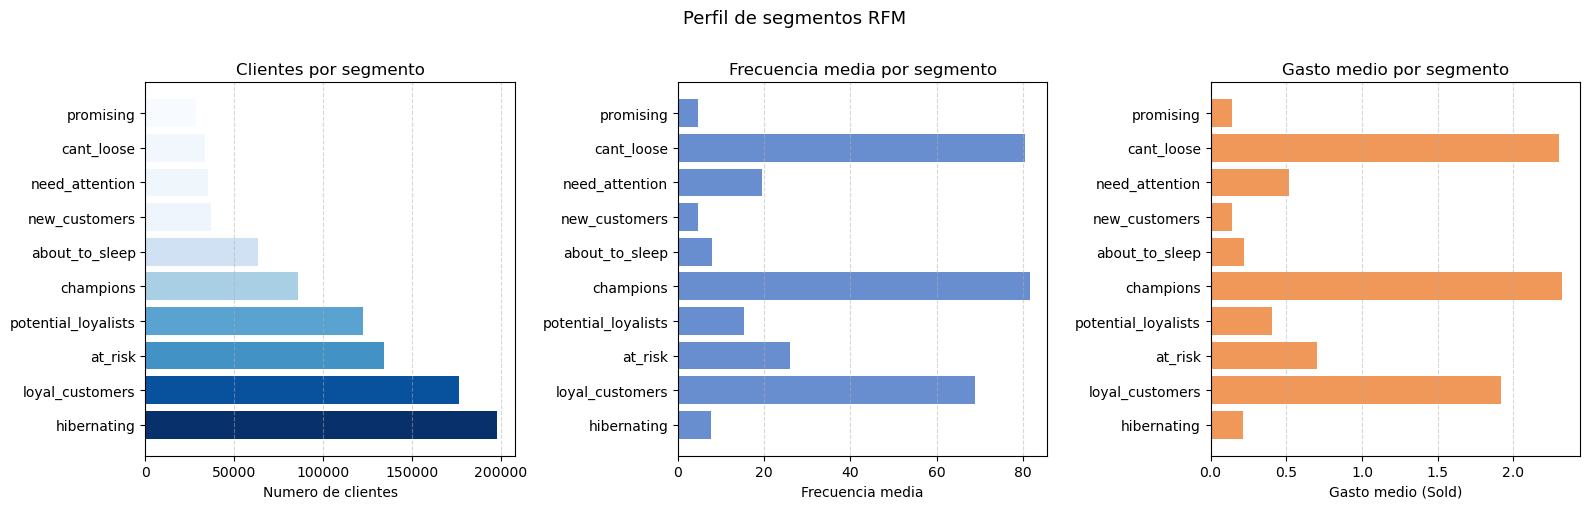

In [9]:
# Traer solo el agregado al driver para visualizacion
perf_pd = perfil_seg.toPandas().set_index("segment")

# Paleta segun tamanio de segmento
norm = plt.Normalize(perf_pd["n_clientes"].min(), perf_pd["n_clientes"].max())
colors = plt.cm.Blues(norm(perf_pd["n_clientes"].values))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Clientes por segmento
axes[0].barh(perf_pd.index, perf_pd["n_clientes"], color=colors)
axes[0].set_xlabel("Numero de clientes")
axes[0].set_title("Clientes por segmento")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Frecuencia media
axes[1].barh(perf_pd.index, perf_pd["freq_media"], color="#4472C4", alpha=0.8)
axes[1].set_xlabel("Frecuencia media")
axes[1].set_title("Frecuencia media por segmento")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

# Gasto medio
axes[2].barh(perf_pd.index, perf_pd["monetary_media"], color="#ED7D31", alpha=0.8)
axes[2].set_xlabel("Gasto medio (Sold)")
axes[2].set_title("Gasto medio por segmento")
axes[2].grid(axis="x", linestyle="--", alpha=0.5)

plt.suptitle("Perfil de segmentos RFM", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

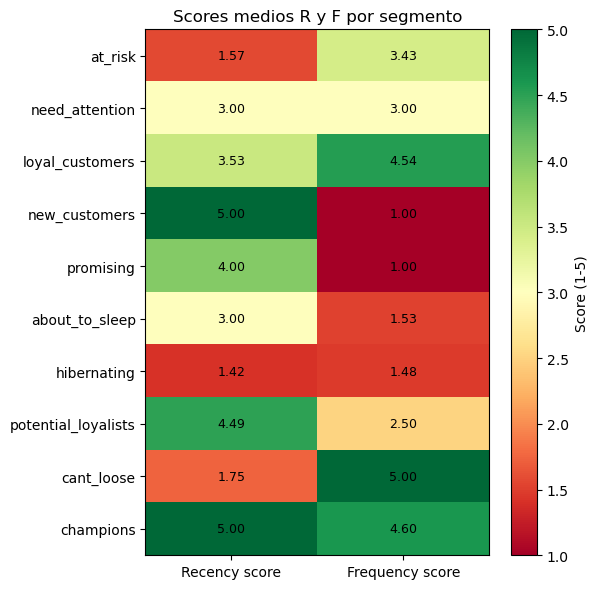

In [10]:
# Heatmap de scores promedio por segmento
import numpy as np

score_pd = (
    df_final.groupBy("segment")
    .agg(
        F.avg("recency_score").alias("R"),
        F.avg("frequency_score").alias("F")
    )
    .toPandas()
    .set_index("segment")
)

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(score_pd.values, cmap="RdYlGn", aspect="auto", vmin=1, vmax=5)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Recency score", "Frequency score"])
ax.set_yticks(range(len(score_pd)))
ax.set_yticklabels(score_pd.index)
for i in range(len(score_pd)):
    for j in range(2):
        ax.text(j, i, f"{score_pd.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Score (1-5)")
ax.set_title("Scores medios R y F por segmento")
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 8. Escritura en capa gold

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Guarda el DataFrame final con la segmentacion RFM en `gold/rfm_segmentos`.

In [11]:
df_final.write.mode("overwrite").parquet(f"{GOLD}/rfm_segmentos")
print("Escritura en gold/rfm_segmentos completada")

# Verificacion
spark.read.parquet(f"{GOLD}/rfm_segmentos").groupBy("segment").count().orderBy(F.col("count").desc()).show()

Escritura en gold/rfm_segmentos completada
+-------------------+------+
|            segment| count|
+-------------------+------+
|        hibernating|198035|
|    loyal_customers|176449|
|            at_risk|134304|
|potential_loyalists|122286|
|          champions| 86105|
|     about_to_sleep| 63394|
|      new_customers| 36655|
|     need_attention| 35405|
|         cant_loose| 33336|
|          promising| 28339|
+-------------------+------+



In [12]:
spark.stop()